# 03 — Modeling, Evaluation & Explainability
Training runs via `python -m src.train` (baseline + tuned LightGBM +
SMOTE-vs-class-weight comparison); this notebook analyses the saved results.

**Why no accuracy anywhere:** with 6% prevalence, predicting "never fraud"
scores 94% accuracy and catches nothing. We tune and select on **PR-AUC**
(average precision) and report Precision / Recall / F1 / ROC-AUC / PR-AUC.

In [1]:
import sys, os, json
sys.path.append(os.path.abspath(".."))
import pandas as pd
from IPython.display import Image, display

cv = json.loads(open("../reports/cv_results.json").read())
print("Cross-validated PR-AUC (5-fold, training data):")
display(pd.Series(cv["cv_pr_auc"]).to_frame("CV PR-AUC"))
print("winner:", cv["winner"])
print("best params:", cv["best_params"])

Cross-validated PR-AUC (5-fold, training data):


,CV PR-AUC
Logistic Regression (balanced),0.1513
LightGBM (class weight),0.2490
LightGBM (SMOTE),0.2722


winner: LightGBM (SMOTE)
best params: {'model__subsample': 0.8, 'model__reg_lambda': 0.1, 'model__num_leaves': 63, 'model__n_estimators': 600, 'model__min_child_samples': 40, 'model__learning_rate': 0.02, 'model__colsample_bytree': 1.0}


## SMOTE vs class weighting

Both address the same problem — the gradient being dominated by the majority
class — from different directions. Here **SMOTE wins** on cross-validated
PR-AUC. Two implementation details that make this comparison honest:

- SMOTE runs **inside** each CV fold (imblearn pipeline). Oversampling before
  the split would leak synthetic copies of validation-fold fraud into training.
- Both variants share identical LightGBM hyperparameters, so the comparison
  isolates the imbalance strategy, not the tuning budget.

In [2]:
test = pd.read_csv("../reports/test_metrics.csv")
threshold = json.loads(open("../models/threshold.json").read())
print(f"Held-out test metrics @ threshold {threshold['threshold']} ({threshold['criterion']}):")
test

Held-out test metrics @ threshold 0.0358 (max F2 (out-of-fold)):


,Model,precision,recall,f1,f2,roc_auc,pr_auc
0,LightGBM (SMOTE),0.1640,0.8865,0.2768,0.4713,0.8561,0.2648
1,LightGBM (class weight),0.1274,0.9514,0.2248,0.4149,0.8410,0.2373
2,Logistic Regression (balanced),0.0645,1.0000,0.1211,0.2562,0.8100,0.1568


## Operating threshold — a business decision, not a default

A missed fraud costs the full claim payout (thousands); a false positive costs
minutes of analyst review. We therefore optimize **F2** (recall weighted 2×
over precision) on out-of-fold training predictions, landing at a low
threshold that catches ~89% of fraud while keeping the review queue at a
workable size. The test set played no role in choosing it.

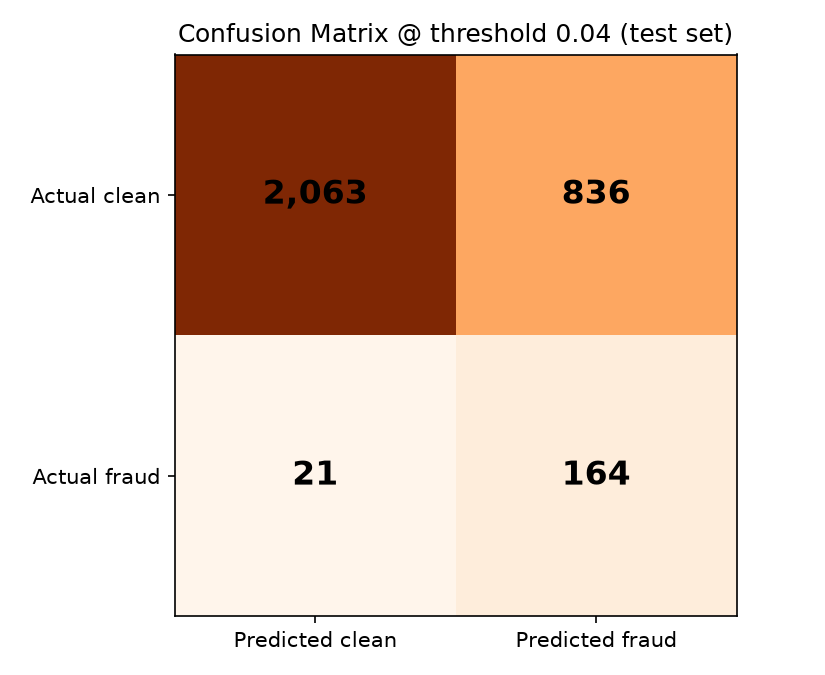

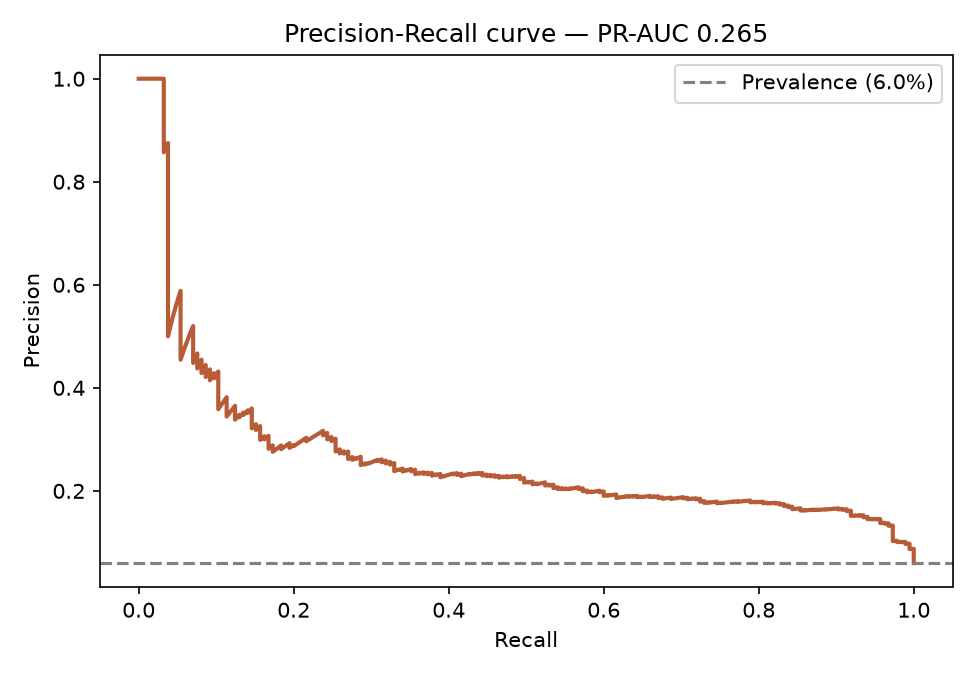

In [3]:
display(Image("figures/confusion_matrix.png"))
display(Image("figures/pr_curve.png"))

## SHAP — global drivers and a flagged claim explained

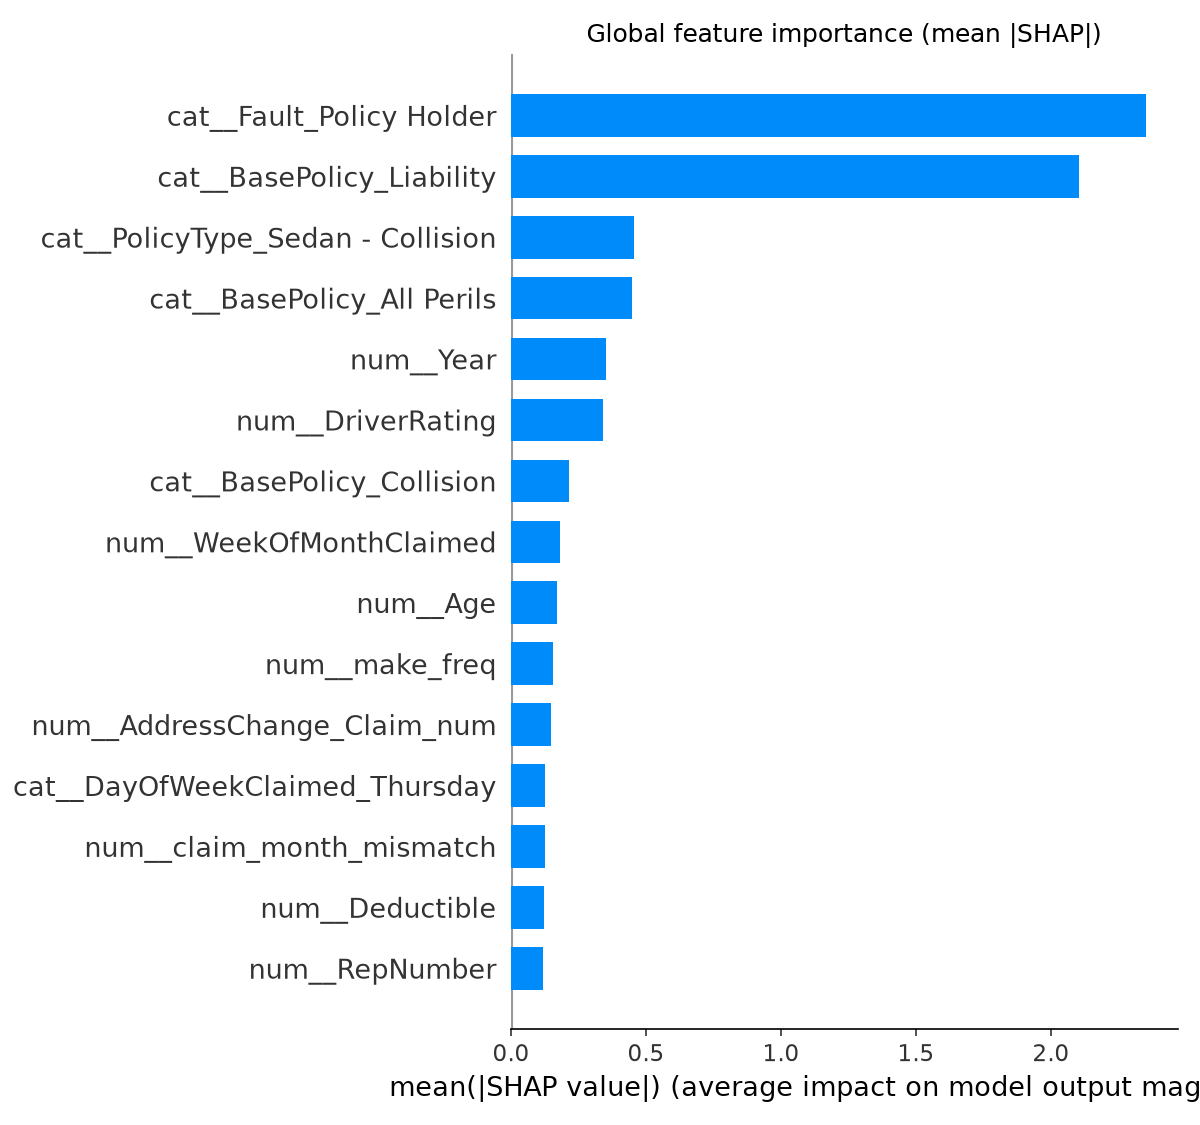

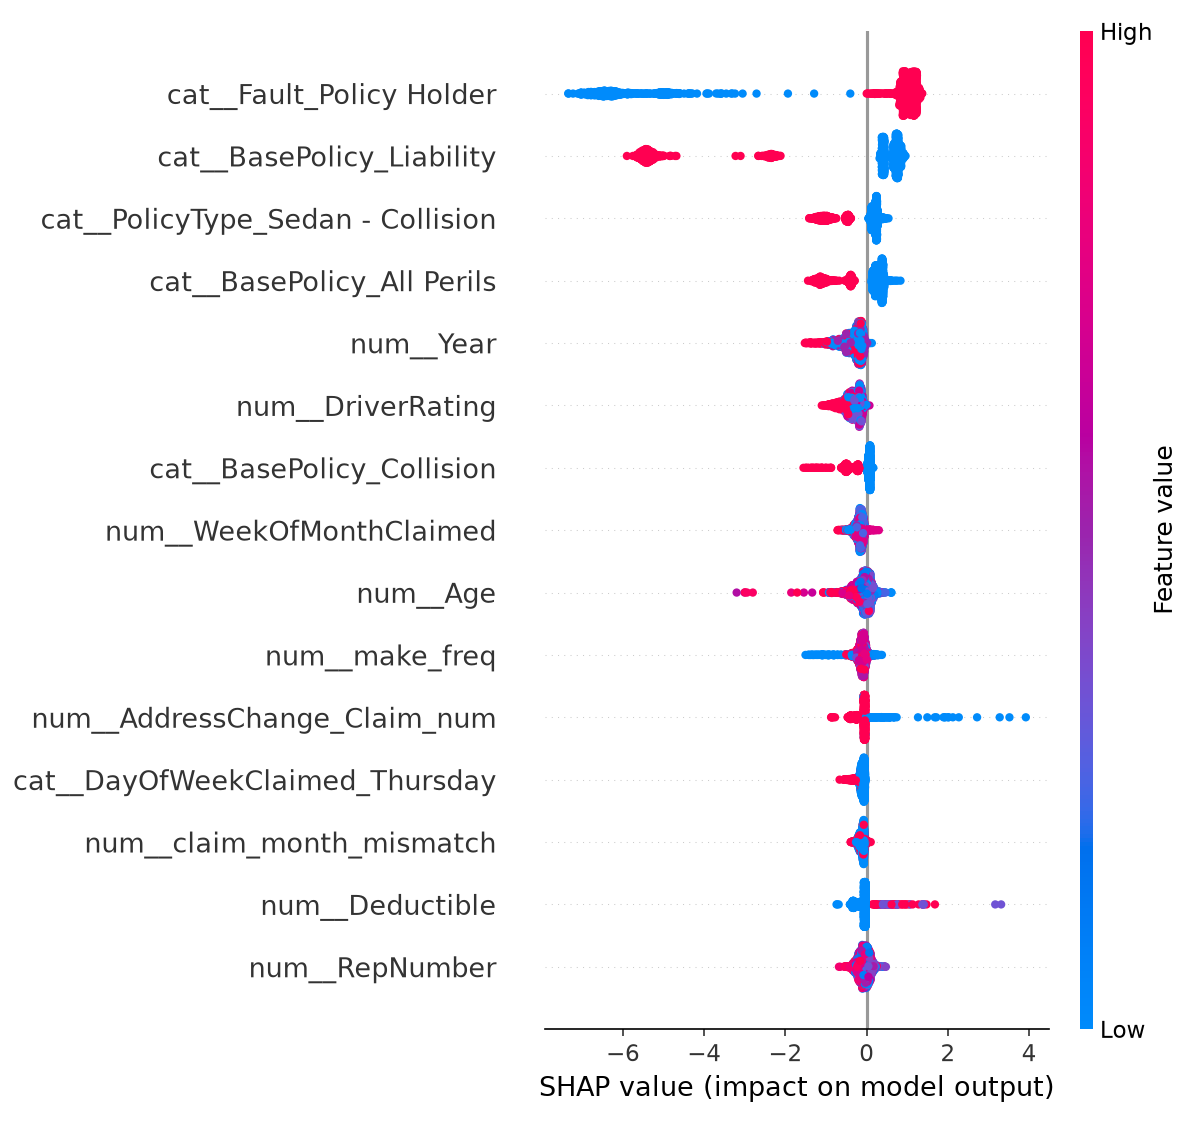

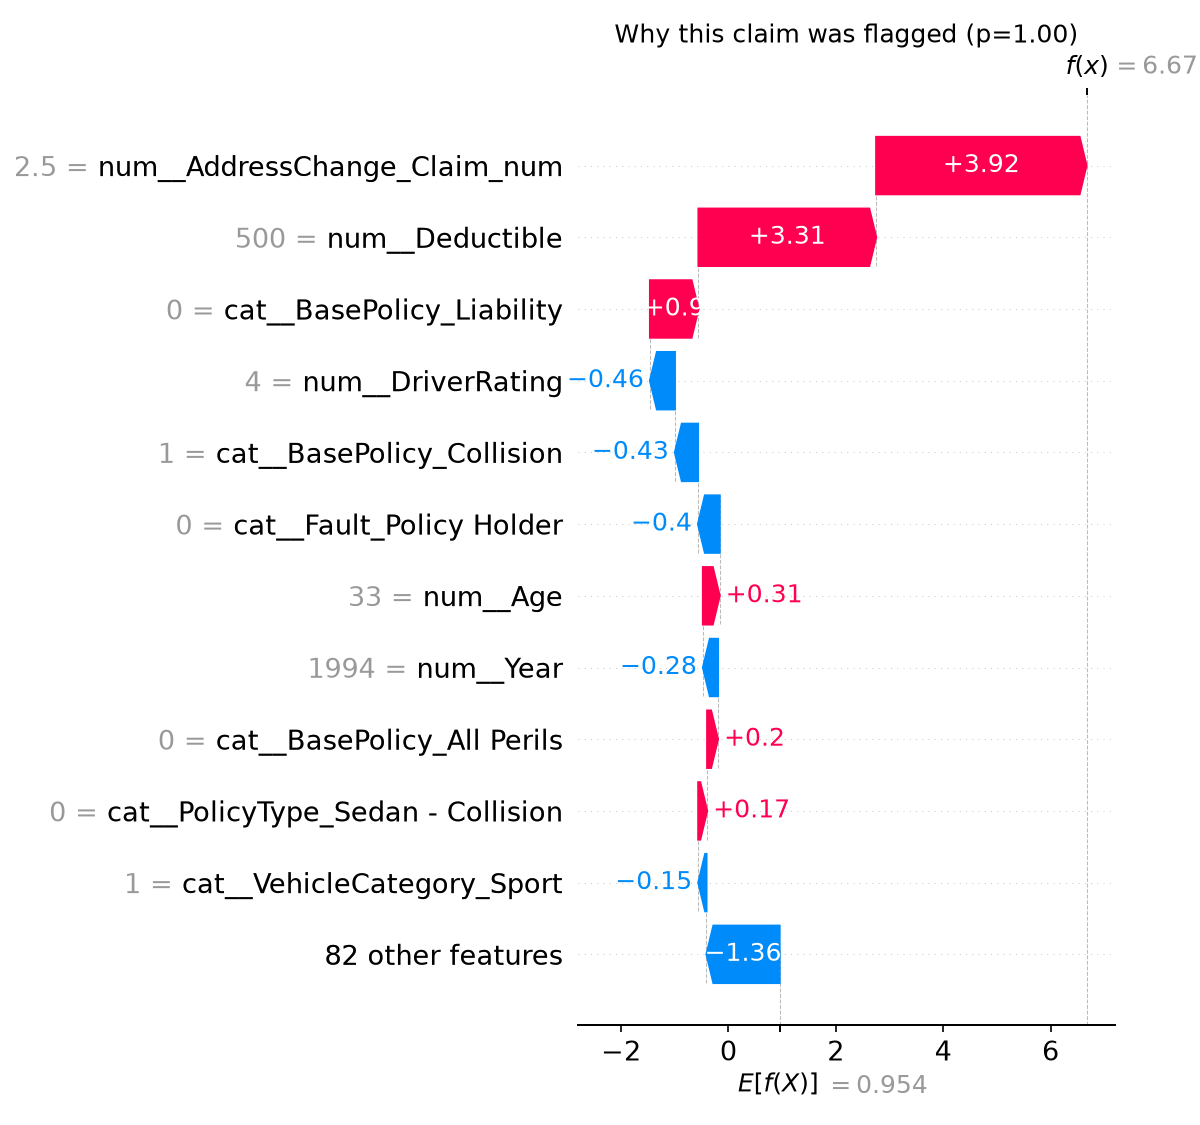

In [4]:
display(Image("figures/shap_global_importance.png"))
display(Image("figures/shap_beeswarm.png"))
display(Image("figures/shap_waterfall_flagged.png"))

The same SHAP machinery powers the API's `top_reasons` field: every flagged
claim ships with its three strongest risk drivers translated into analyst
language (see `src/explain.py::reason_strings`).